In [5]:
import pandas as pd

#Let's read a patient's file to see what the format is
df_sample = pd.read_csv("../data/raw/training/training_setA/p000001.psv", sep="|")
print(df_sample.shape)
print(df_sample.columns.tolist())
df_sample.head()

(54, 41)
['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2', 'BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST', 'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine', 'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate', 'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb', 'PTT', 'WBC', 'Fibrinogen', 'Platelets', 'Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS', 'SepsisLabel']


,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,1,0
1,97.0,95.0,NaN,98.0,75.33,NaN,19.0,NaN,NaN,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,2,0
2,89.0,99.0,NaN,122.0,86.00,NaN,22.0,NaN,NaN,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,3,0
3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,NaN,24.0,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,4,0
4,103.0,88.5,NaN,122.0,91.33,NaN,24.5,NaN,NaN,NaN,...,NaN,NaN,NaN,83.14,0,NaN,NaN,-0.03,5,0


In [2]:
import glob

def load_all_patients(folder):
    files = sorted(glob.glob(f"{folder}/*.psv"))
    rows = []
    for i, f in enumerate(files):
        d = pd.read_csv(f, sep="|")
        d["patient_id"] = i
        rows.append(d)
    return pd.concat(rows, ignore_index=True)

df_A = load_all_patients("../data/raw/training/training_setA")
print(df_A.shape)

(790215, 42)


In [3]:
print(df_A["patient_id"].nunique())

20336


In [6]:
df_B = load_all_patients("../data/raw/training/training_setB")

#Reschedule the Set B patient's appointment to avoid a clash with Set A slot.
df_B["patient_id"] = df_B["patient_id"] + df_A["patient_id"].max() + 1

#Combine both into a single large table.
df = pd.concat([df_A, df_B], ignore_index=True)

print(df.shape)
print(df["patient_id"].nunique(), "total unique patients")

(1552210, 42)
40336 total unique patients


In [7]:
df.to_parquet("../data/processed/sepsis_raw_combined.parquet")
print("saved!")

saved!


In [8]:
print(df["SepsisLabel"].value_counts(normalize=True))

SepsisLabel
0    0.982015
1    0.017985
Name: proportion, dtype: float64


In [9]:
patients_with_sepsis = df.groupby("patient_id")["SepsisLabel"].max()
print(patients_with_sepsis.mean())

0.07268940896469656


In [10]:
# Check which percentage of values are missing in each column
missing_pct = df.isna().mean().sort_values(ascending=False) * 100

# Print the top 15 columns with highest missing percentage
print(missing_pct.head(15))

Bilirubin_direct    99.807371
Fibrinogen          99.340167
TroponinI           99.047745
Bilirubin_total     98.509158
Alkalinephos        98.393194
AST                 98.377604
Lactate             97.329872
PTT                 97.055875
SaO2                96.549372
EtCO2               96.286843
Phosphate           95.986303
HCO3                95.810618
Chloride            95.460279
BaseExcess          94.579020
PaCO2               94.440121
dtype: float64


In [11]:
# List of vital signs that are continuously monitored (not lab tests)
vitals = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp"]

# Print missing percentage only for these vital sign columns
print(missing_pct[vitals])

HR        9.882619
O2Sat    13.061119
Temp     66.162697
SBP      14.576958
MAP      12.451279
DBP      31.345887
Resp     15.354559
dtype: float64


In [12]:
# Find all patients who developed sepsis at any point
septic_patients = df[df["SepsisLabel"] == 1]["patient_id"].unique()

# Print how many such patients exist
print(len(septic_patients), "patients developed sepsis")

2932 patients developed sepsis


In [13]:
# Find, for each septic patient, the hour when sepsis first started (onset hour)
onset_hours = df[df["SepsisLabel"] == 1].groupby("patient_id")["ICULOS"].min()

# Create an empty list to store each patient's data window before onset
trajectories = []

# Loop through each septic patient's onset time
for pid, onset in onset_hours.items():
    # Select only this patient's data, from 12 hours before onset up to onset
    pdata = df[(df["patient_id"] == pid) & (df["ICULOS"] >= onset - 12) & (df["ICULOS"] <= onset)]
    pdata = pdata.copy()  # make a safe copy to avoid warnings
    # Create a new column: how many hours before onset this row is (0 = onset hour)
    pdata["hours_before_onset"] = pdata["ICULOS"] - onset
    trajectories.append(pdata)

# Combine all patients' windows into one big table
traj_df = pd.concat(trajectories)

print(traj_df.shape)

(29256, 43)


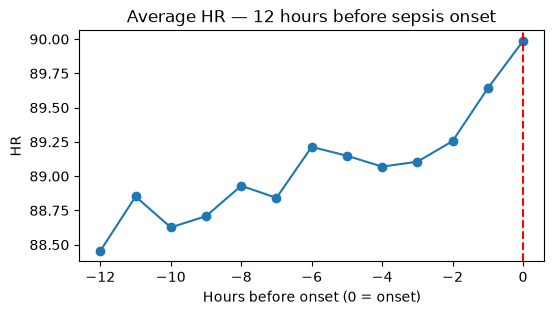

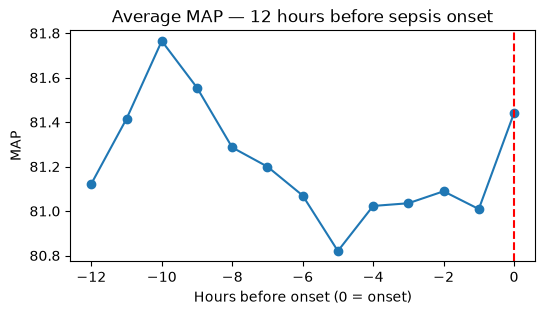

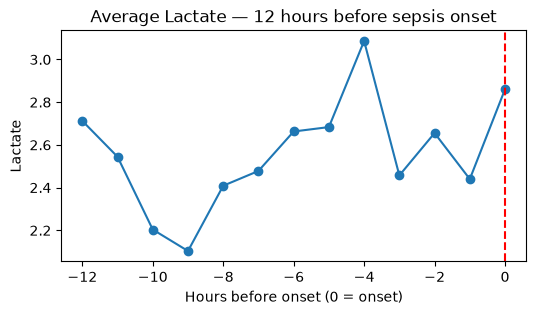

In [14]:
# Import the plotting library
import matplotlib.pyplot as plt

# List of vital signs we want to visualize the trend for
cols_to_plot = ["HR", "MAP", "Lactate"]

# Loop through each vital sign and create a separate plot
for col in cols_to_plot:
    # Group all patients by "hours_before_onset" and calculate the average value at each hour
    avg_trend = traj_df.groupby("hours_before_onset")[col].mean()
    
    # Create a new figure (chart) with a specific size
    plt.figure(figsize=(6,3))
    
    # Plot the average trend line, with circular markers at each point
    avg_trend.plot(marker='o')
    
    # Add a title to the chart showing which vital sign this is
    plt.title(f"Average {col} — 12 hours before sepsis onset")
    
    # Label the x-axis (time) and y-axis (the vital sign value)
    plt.xlabel("Hours before onset (0 = onset)")
    plt.ylabel(col)
    
    # Draw a red dashed vertical line at 0 to mark the onset moment
    plt.axvline(0, color='red', linestyle='--')
    
    # Display the chart
    plt.show()